In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/3
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '3' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第3章 画面表示の練習とブートローダ — 演習問題 (*Chapter 3 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著）第3章「画面表示の練習とブートローダ」で学んだ、QEMUモニタデバッグ（`info registers`, `xp`）、x86-64汎用レジスタおよび制御レジスタ（CR0/CR3/CR4）、32ビットゼロ拡張則、最小カーネル読み込みとエントリポイントへのジャンプ、System V AMD64 ABI の Red Zone（128バイト）と `-mno-red-zone` の必須性、UEFI GOP（Graphics Output Protocol）によるフレームバッファ取得と PixelsPerScanLine ストライド数理、ピクセルフォーマット（RGB vs BGR）、ブートローダからカーネルへの引数引き渡し ABI（RDI, RSI）、`EFI_STATUS` のエラーハンドリングと `reinterpret_cast`、そしてポインタ間接参照のアセンブリ言語展開・SIBアドレッシングと `volatile` の役割を総動員して解く総合演習問題です。

---

## 🗺️ 第3章 全体像・知識ロードマップ

```mermaid
graph TD
    subgraph S1["3.1〜3.2: ハードウェア検査とレジスタアーキテクチャ"]
        A["3.1 QEMUモニタ<br/>(info registers / xp 物理メモリ検査)"] --> B["3.2 x86-64 レジスタ<br/>(RAX〜R15 / 32bitゼロ拡張 / CR0-CR4)"]
    end

    subgraph S2["3.3: カーネル実行とABIの罠"]
        B --> C["3.3 初めてのカーネル<br/>(0x100000配置 / ExitBootServices / ジャンプ)"]
        C --> D["コラム3.1 Red Zone<br/>(128バイトスタック領域 / 割り込み破壊 / -mno-red-zone)"]
    end

    subgraph S3["3.4〜3.5: UEFI GOP とフレームバッファ描画"]
        D --> E["3.4 ブートローダからピクセルを描く<br/>(GOP / PixelsPerScanLine / RGB vs BGR)"]
        E --> F["3.5 カーネルからピクセルを描く<br/>(引数渡し RDI/RSI / ストライプ描画)"]
    end

    subgraph S4["3.6〜3.7: エラーハンドリングとアセンブリレベルのポインタ"]
        F --> G["3.6 エラー処理 & ポインタキャスト<br/>(EFI_STATUS 最上位ビット / reinterpret_cast)"]
        G --> H["3.7 ポインタとアセンブリ言語<br/>(SIBアドレッシング / volatile MMIO / SIMD)"]
    end

    H --> I["第3章 演習問題<br/>(理論・計算・C++20検証・10問クイズ・レーダー)"]

    style S1 fill:#E3F2FD,stroke:#1E88E5,stroke-width:2px
    style S2 fill:#FFF3E0,stroke:#FB8C00,stroke-width:2px
    style S3 fill:#EDE7F6,stroke:#8E24AA,stroke-width:2px
    style S4 fill:#FCE4EC,stroke:#C2185B,stroke-width:2px
    style I fill:#E8F5E9,stroke:#43A047,stroke-width:3px
```

---

## 🎯 演習の到達目標 (Learning Objectives)

1. **QEMUモニタと x86-64 レジスタ仕様の完全理解**:
   - `info registers` および `xp` による物理メモリ検査を使いこなし、64ビット汎用レジスタに対する32ビット書き込み時の「上位32ビット自動ゼロクリア則」を論理説明できる。
2. **カーネルブート遷移と Red Zone の危険性の把握**:
   - `ExitBootServices()` によるブートサービス停止とエントリポイントジャンプの仕組みを把握し、割り込み発生時に Red Zone が上書き破壊される致命的メカニズムと `-mno-red-zone` の必然性を説明できる。
3. **UEFI GOP フレームバッファとストライド幾何計算の修得**:
   - `PixelsPerScanLine` (走査線幅) が `HorizontalResolution` と異なる理由を理解し、ピクセル座標 $(x, y)$ の物理バイトオフセット計算式 $4 	imes (y 	imes 	ext{ppsl} + x)$ を導出できる。
4. **System V AMD64 ABI とポインタのアセンブリ展開の体得**:
   - 整数・ポインタ引数が RDI, RSI 経由でカーネルへ引き渡される規則、および C言語ポインタ演算が x86-64 の SIB (Scale-Index-Base) アドレッシング命令にマップされ、MMIO/VRAM で `volatile` が必須となる理由を完全に論述できる。


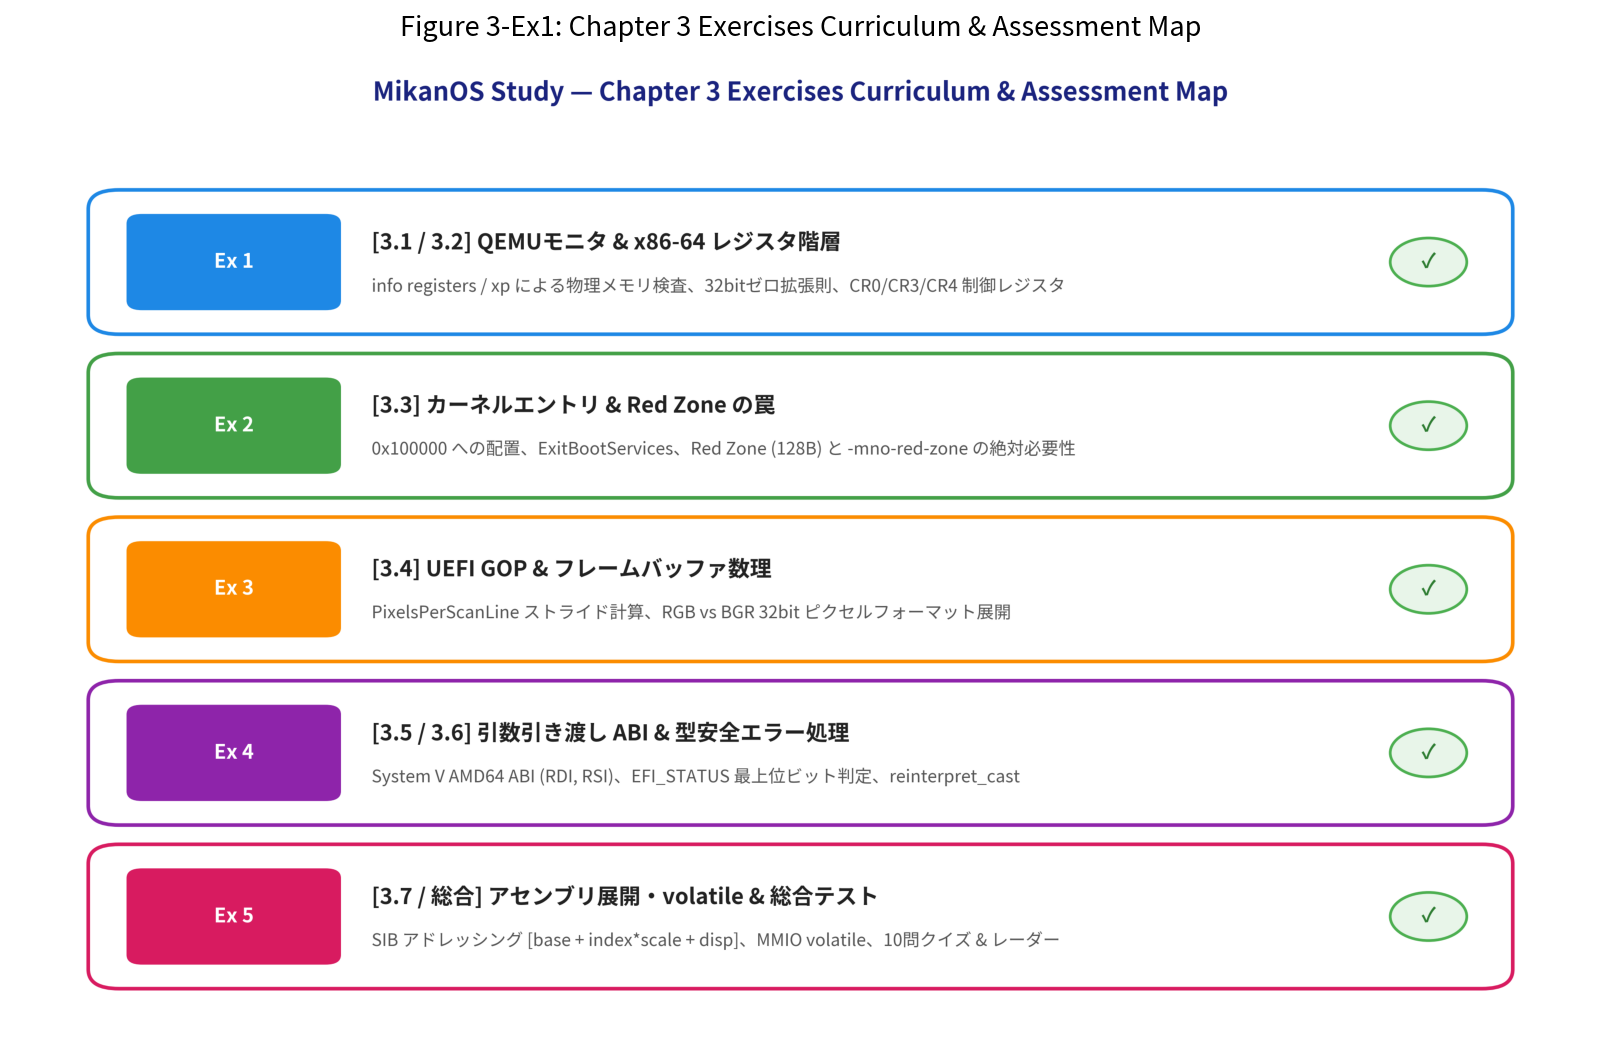

In [2]:
import matplotlib.pyplot as plt
from pathlib import Path
from common import plot_chapter3_exercises_summary

summary_fig_path = Path("result/fig3_ex1_exercises_summary.png")
plot_chapter3_exercises_summary(summary_fig_path)

img = plt.imread(summary_fig_path)
plt.figure(figsize=(14, 8.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 3-Ex1: Chapter 3 Exercises Curriculum & Assessment Map", fontsize=13, pad=12)
plt.show()


---

## 📝 パート 1: システム理論・ハードウェアアーキテクチャ演習 (穴埋め・論理検証)

低レイヤOS開発におけるハードウェア制御、x86-64 レジスタ階層、UEFI GOP フレームバッファ、System V AMD64 ABI 規約の理解を問う演習問題です。

### 問題 1-1: QEMUモニタコマンドと低レイヤデバッグ (節 3.1)

QEMUモニタでは、仮想マシンの実行状態を外部から検査するための多彩なコマンドが用意されています。
以下の各コマンドが果たす役割を辞書形式で定義し、バリデータで検証してください：
- `"info registers"`: 全レジスタおよび制御レジスタのダンプ
- `"xp"`: 物理メモリアドレスの直接ダンプ (eXamine Physical)
- `"x"`: 仮想メモリアドレスのダンプ (eXamine Virtual)


In [3]:
from common import Chapter3TheoryValidator

# === 問題 1-1 解答セル ===
my_qemu_commands = {
    "info registers": "全レジスタおよび制御レジスタのダンプ (Dump CPU Registers)",
    "xp": "物理メモリアドレスのダンプ (eXamine Physical memory)",
    "x": "仮想メモリアドレスのダンプ (eXamine Virtual memory)",
}

ok, msg = Chapter3TheoryValidator.validate_qemu_monitor_commands(my_qemu_commands)
print(f"判定結果: {'PASS' if ok else 'FAIL'}")
print(msg)
assert ok, "問題 1-1 の検証に失敗しました。"


判定結果: PASS
正解！QEMUモニタの主要検査コマンドの役割を正確に同定しました。


### 問題 1-2: x86-64 レジスタの32ビット書き込みゼロ拡張則 (節 3.2)

x86-64 アーキテクチャでは、上位互換性とレジスタリネーミングの最適化のために、**「32ビットサブレジスタ（例: EAX, EBX, R8D）への書き込みを行うと、対応する64ビットレジスタの上位32ビットが自動的にすべてゼロクリア（ゼロ拡張）される」** という決定的な仕様が存在します。

初期値として `RAX = 0xFFFFFFFFFFFFFFFF` が入っている状態で、`MOV EAX, 0x12345678` を実行した後の `RAX` の最終的な64ビット値を算出し、検証してください。


In [4]:
# === 問題 1-2 解答セル ===
my_zero_ext_sim = {
    "initial_rax": 0xFFFFFFFFFFFFFFFF,
    "write_eax": 0x12345678,
    "final_rax": 0x0000000012345678,  # 上位32ビットがゼロクリアされる！
}

ok, msg = Chapter3TheoryValidator.validate_register_zero_extension(my_zero_ext_sim)
print(f"判定結果: {'PASS' if ok else 'FAIL'}")
print(msg)
assert ok, "問題 1-2 の検証に失敗しました。"


判定結果: PASS
正解！32ビットサブレジスタ書き込み時の上位32ビットゼロクリア（ゼロ拡張）挙動を正確に計算しました。


### 問題 1-3: System V AMD64 ABI Red Zone と -mno-red-zone の必然性 (節 3.3)

System V AMD64 ABI では、スタックポインタ `RSP` の直下に **128 バイト** のスクラッチ領域（Red Zone）が規定されています。
- 通常のユーザー空間アプリでは、スタック拡張（`sub rsp, N`）を省略して高速化できます。
- しかしカーネル空間では、非同期ハードウェア割り込みが発生した瞬間に CPU が自動的にスタックへ割り込みフレーム（RIP, CS, RFLAGS 等）を push するため、Red Zone が上書き破壊されます。
- したがって、カーネルのコンパイルには必ず **`-mno-red-zone`** が不可欠です。

以下の辞書を完成させて検証してください。


In [5]:
# === 問題 1-3 解答セル ===
my_red_zone_rules = {
    "size_bytes": 128,
    "direction": "RSP より下 (below RSP, negative offset)",
    "compiler_flag": "-mno-red-zone",
    "safe_for_interrupts": False,  # 割り込みで破壊されるため危険
}

ok, msg = Chapter3TheoryValidator.validate_red_zone_rules(my_red_zone_rules)
print(f"判定結果: {'PASS' if ok else 'FAIL'}")
print(msg)
assert ok, "問題 1-3 の検証に失敗しました。"


判定結果: PASS
正解！Red Zone の仕様とカーネルにおける -mno-red-zone の絶対必要性を正確に理解しています。


### 問題 1-4: UEFI GOP フレームバッファのストライド・オフセット数理 (節 3.4)

画面解像度が $800 	imes 600$ で、GPUバスアライメントのために走査線あたりのピクセル幅 $	ext{PixelsPerScanLine} = 832$ となっている環境を想定します。1ピクセルは 32ビット（4バイト）です。

1. 座標 $(x, y) = (100, 50)$ におけるピクセルのバイトオフセット
2. フレームバッファ全体の必要総バイト数

を計算し、辞書で定義して検証してください。


In [6]:
# === 問題 1-4 解答セル ===
h_res = 800
v_res = 600
ppsl = 832
bpp = 4
target_x = 100
target_y = 50

my_gop_math = {
    "h_res": h_res,
    "v_res": v_res,
    "ppsl": ppsl,
    "bytes_per_pixel": bpp,
    "target_x": target_x,
    "target_y": target_y,
    "pixel_byte_offset": bpp * (target_y * ppsl + target_x),
    "total_fb_size": bpp * ppsl * v_res,
}

ok, msg = Chapter3TheoryValidator.validate_gop_framebuffer_math(my_gop_math)
print(f"判定結果: {'PASS' if ok else 'FAIL'}")
print(msg)
print(f"ピクセル (100, 50) のバイトオフセット: {my_gop_math['pixel_byte_offset']:#x} ({my_gop_math['pixel_byte_offset']} バイト)")
print(f"フレームバッファ総サイズ: {my_gop_math['total_fb_size'] / 1024 / 1024:.2f} MiB")
assert ok, "問題 1-4 の検証に失敗しました。"


判定結果: PASS
正解！PixelsPerScanLine（ストライド）を考慮したフレームバッファアドレス数理を完璧に計算しました。
ピクセル (100, 50) のバイトオフセット: 0x28b90 (166800 バイト)
フレームバッファ総サイズ: 1.90 MiB


### 問題 1-5: System V AMD64 ABI レジスタ引数引き渡し (節 3.5)

ブートローダからカーネル `KernelMain(uint64_t fb_base, uint64_t fb_size)` へ引数を渡す際、System V AMD64 ABI において引数が格納される 64ビットレジスタの順序（第1〜第6引数）をリストで定義してください。


In [7]:
# === 問題 1-5 解答セル ===
my_abi_arg_regs = ["RDI", "RSI", "RDX", "RCX", "R8", "R9"]

ok, msg = Chapter3TheoryValidator.validate_system_v_abi_args(my_abi_arg_regs)
print(f"判定結果: {'PASS' if ok else 'FAIL'}")
print(msg)
assert ok, "問題 1-5 の検証に失敗しました。"


判定結果: PASS
正解！System V AMD64 ABI の第1〜第6引数レジスタ順序（RDI, RSI, RDX, RCX, R8, R9）を正確に同定しました。


---

## 💻 パート 2: Python / 低レイヤシミュレーション実装演習

### 問題 2-1: GOP フレームバッファ RGB/BGR ピクセル描画エンジンの実装 (節 3.4, 3.5)

以下の仕様を満たす Python クラス `SimpleFrameBuffer` を実装してください：
1. `__init__(width, height, ppsl, pixel_format)`:
   - `pixel_format` は `"RGB"` または `"BGR"`
   - 内部バッファ `bytearray(ppsl * height * 4)` を確保
2. `draw_pixel(x, y, r, g, b)`:
   - 範囲外チェック（$0 \le x < 	ext{width}$, $0 \le y < 	ext{height}$）
   - フォーマットに応じて RGB（[R, G, B, 0]）または BGR（[B, G, R, 0]）で書き込み
3. `get_pixel(x, y)`:
   - 該当座標の論理色 `(r, g, b)` タプルを返す


In [8]:
# === 問題 2-1 解答セル ===
class SimpleFrameBuffer:
    def __init__(self, width: int, height: int, ppsl: int, pixel_format: str = "RGB"):
        self.width = width
        self.height = height
        self.ppsl = ppsl
        self.pixel_format = pixel_format.upper()
        self.buffer = bytearray(ppsl * height * 4)

    def draw_pixel(self, x: int, y: int, r: int, g: int, b: int) -> None:
        if not (0 <= x < self.width and 0 <= y < self.height):
            return
        offset = 4 * (y * self.ppsl + x)
        if self.pixel_format == "RGB":
            self.buffer[offset + 0] = r
            self.buffer[offset + 1] = g
            self.buffer[offset + 2] = b
            self.buffer[offset + 3] = 0
        else:  # BGR
            self.buffer[offset + 0] = b
            self.buffer[offset + 1] = g
            self.buffer[offset + 2] = r
            self.buffer[offset + 3] = 0

    def get_pixel(self, x: int, y: int) -> tuple[int, int, int]:
        if not (0 <= x < self.width and 0 <= y < self.height):
            return (0, 0, 0)
        offset = 4 * (y * self.ppsl + x)
        if self.pixel_format == "RGB":
            return (self.buffer[offset + 0], self.buffer[offset + 1], self.buffer[offset + 2])
        else:
            return (self.buffer[offset + 2], self.buffer[offset + 1], self.buffer[offset + 0])

# テスト検証
fb_rgb = SimpleFrameBuffer(800, 600, 832, "RGB")
fb_bgr = SimpleFrameBuffer(800, 600, 832, "BGR")

fb_rgb.draw_pixel(10, 20, 255, 128, 64)
fb_bgr.draw_pixel(10, 20, 255, 128, 64)

# 論理色タプルの一致検証
assert fb_rgb.get_pixel(10, 20) == (255, 128, 64)
assert fb_bgr.get_pixel(10, 20) == (255, 128, 64)

# 生メモリ配置の検証
off = 4 * (20 * 832 + 10)
assert fb_rgb.buffer[off:off+3] == bytearray([255, 128, 64])  # RGB
assert fb_bgr.buffer[off:off+3] == bytearray([64, 128, 255])  # BGR

print("✅ SimpleFrameBuffer のストライド・RGB/BGR メモリ配置テストに合格しました！")


✅ SimpleFrameBuffer のストライド・RGB/BGR メモリ配置テストに合格しました！


### 問題 2-2: x86-64 SIB (Scale-Index-Base) アドレッシング計算機の実装 (節 3.7)

x86-64 のメモリアドレッシングモード SIB は以下の数理で実効アドレス（Effective Address）を計算します：
$$\text{EffectiveAddress} = \text{Base} + (\text{Index} \times \text{Scale}) + \text{Displacement}$$

Scale に指定可能な値は $1, 2, 4, 8$ のいずれかです。
この数理を実装し、`Chapter3TheoryValidator.validate_pointer_assembly_sib` で検証してください。


In [9]:
# === 問題 2-2 解答セル ===
def calc_sib_address(base: int, index: int, scale: int, disp: int = 0) -> int:
    if scale not in (1, 2, 4, 8):
        raise ValueError(f"Invalid scale: {scale}. Must be 1, 2, 4, or 8.")
    return base + (index * scale) + disp

base_addr = 0x10000000
idx = 42
scale_factor = 4
displacement = 16

my_sib_dict = {
    "base": base_addr,
    "index": idx,
    "scale": scale_factor,
    "disp": displacement,
    "effective_address": calc_sib_address(base_addr, idx, scale_factor, displacement),
}

ok, msg = Chapter3TheoryValidator.validate_pointer_assembly_sib(my_sib_dict)
print(f"判定結果: {'PASS' if ok else 'FAIL'}")
print(msg)
print(f"計算実効アドレス: {my_sib_dict['effective_address']:#x}")
assert ok, "問題 2-2 の検証に失敗しました。"


判定結果: PASS
正解！SIB (Scale-Index-Base) アドレッシングの実効アドレス計算を正確に算出しました。
計算実効アドレス: 0x100000b8


---

## ⚙️ パート 3: C++20 スタンドアロン検証コードの対話型コンパイル & 実行

MikanOS 第3章で学んだ主要なハードウェア・レジスタ・スタック・フレームバッファ仕様をホスト側 C++20（`src/ch03/os_chapter3_exercises.cpp`）でスタンドアロン実装し、検証します。

以下のセルを実行して直接コンパイル・実行し、全項目が PASS することを確認してください。


In [10]:
import subprocess
from pathlib import Path

cpp_src = Path("../src/ch03/os_chapter3_exercises.cpp") if Path.cwd().name == "3" else Path("src/ch03/os_chapter3_exercises.cpp")
bin_out = Path("/tmp/ch03_exercises_runner")

print(f"Compiling C++20 verification code: {cpp_src} ...")
cmd_build = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-Wpedantic", str(cpp_src), "-o", str(bin_out)]
res_build = subprocess.run(cmd_build, capture_output=True, text=True)
if res_build.returncode != 0:
    print("Compilation Error:\n", res_build.stderr)
    raise RuntimeError("C++20 compilation failed.")

print("Compilation successful! Running verification tests...\n")
res_run = subprocess.run([str(bin_out), "--test"], capture_output=True, text=True)
print(res_run.stdout)
assert res_run.returncode == 0, "C++20 test suite failed."
print("✅ C++20 全単体テストが正常に完了しました！")


Compiling C++20 verification code: ../src/ch03/os_chapter3_exercises.cpp ...


Compilation successful! Running verification tests...

[Info] Running in test mode.
 MikanOS Chapter 3 Comprehensive Exercises (C++20)

[1] Verifying x86-64 Register Zero-Extension Rule...
    -> Passed: 32-bit write zero-extension and sub-register preservation verified.

[2] Verifying System V AMD64 ABI Red Zone Behavior...
    -> Passed: Red Zone corruption by asynchronous interrupt demonstrated.
    -> Passed: -mno-red-zone stack frame safety verified.

[3] Verifying GOP Framebuffer Stride & Formats (RGB vs BGR)...
    -> Passed: Framebuffer stride math & RGB/BGR memory layout verified.

[4] Verifying System V AMD64 ABI Calling Convention...
    -> Passed: KernelMain(fb_base in RDI, fb_size in RSI) handoff verified.

[5] Verifying UEFI Status Code & Casts...
    -> Passed: EFI_STATUS high-bit error macro & reinterpret_cast verified.

[6] Verifying SIB (Scale-Index-Base) Effective Address Computation...
    -> Passed: SIB address computation [base + index*4 + 16] verified.

 All Chap

---

## 🎓 パート 4: 第3章 総合理解度チェックテスト (10問自己採点クイズ)

第3章（3.1〜3.7）の全7節を完全網羅した 10問の客観選択式クイズです。
各問題の選択肢を確認し、次のセルで解答を入力して自己採点してください（合格基準: 80%以上）。


In [11]:
from common import Chapter3Quiz

quiz = Chapter3Quiz()

print("=" * 70)
print(f" 第3章 画面表示の練習とブートローダ 総合理解度チェックテスト (全 {len(quiz.questions)} 問)")
print("=" * 70 + "\n")

for q in quiz.questions:
    print(f"【問 {q.question_id}】 (節 {q.section}: {q.topic})")
    print(f"{q.question}")
    for idx, opt in enumerate(q.options):
        print(f"  ({idx}) {opt}")
    print()


 第3章 画面表示の練習とブートローダ 総合理解度チェックテスト (全 10 問)

【問 1】 (節 3.1: QEMUモニタコマンドとデバッグ (info registers & xp))
QEMUモニタにおけるコマンドの役割として正しいものはどれか？
  (0) info registers はOSのファイル一覧を表示し、xp は仮想記憶空間のみを検査する
  (1) info registers は全CPU汎用レジスタ・制御レジスタ・EFLAGSの状態をダンプし、xp は物理アドレスのメモリ内容を指定フォーマットでダンプする
  (2) xp はブレークポイントを設定し、c はプログラムを強制終了する
  (3) x コマンドは物理メモリダンプ専用で、xp コマンドは仮想メモリダンプ専用である

【問 2】 (節 3.2: x86-64 レジスタ階層と32ビットゼロ拡張則)
x86-64 の 64ビット汎用レジスタ（RAX 等）に対する32ビットサブレジスタ（EAX）書き込み時の動作として正しいものはどれか？
  (0) EAXに書き込むと、RAXの上位32ビットは変更されず以前の値がそのまま保持される
  (1) EAXに書き込むと、RAXの上位32ビットは自動的にすべてゼロクリア（ゼロ拡張）される
  (2) EAXに書き込むと、RAXの最上位ビットが符号拡張されて上位32ビットにコピーされる
  (3) EAXへの書き込みは64ビットモードでは禁止されており一般保護例外 (#GP) が発生する

【問 3】 (節 3.2: x86-64 制御レジスタ (CR0, CR3, CR4))
x86-64 の制御レジスタ CR0 および CR3 の役割の組み合わせとして正しいものはどれか？
  (0) CR0 は浮動小数点演算の結果を保持し、CR3 はタイマ割り込み周期を設定する
  (1) CR0 はプロテクトモード有効化 (PE) やページング有効化 (PG) などのCPU動作モードを制御し、CR3 は4階層ページテーブルの最上位 (PML4) 物理アドレスを保持する
  (2) CR0 はスタックポインタであり、CR3 は命令ポインタである
  (3) CR0 はカーネル引数レジスタであり、CR3 はシステムコール番号レジスタである

【問 4】 (節 

In [12]:
# === 解答入力セル ===
# 各問題の正解と思われる選択肢の番号 (0〜3) を入力してください
my_answers = {
    1: 1,  # 問1: QEMUモニタ info registers & xp
    2: 1,  # 問2: x86-64 32ビットゼロ拡張則
    3: 1,  # 問3: CR0 / CR3 制御レジスタ
    4: 0,  # 問4: カーネルロードとエントリポイントジャンプ
    5: 1,  # 問5: Red Zone と -mno-red-zone
    6: 1,  # 問6: GOP PixelsPerScanLine ストライド
    7: 1,  # 問7: GOP ピクセルフォーマット (RGB vs BGR)
    8: 1,  # 問8: System V AMD64 ABI 引数レジスタ (RDI, RSI)
    9: 1,  # 問9: EFI_STATUS 最上位ビット & reinterpret_cast
    10: 1, # 問10: SIB アドレッシング & volatile MMIO
}

eval_result = quiz.evaluate(my_answers)

print("=" * 70)
print(f" 採点結果: {eval_result['correct_count']} / {eval_result['total_questions']} 正解 ({eval_result['percentage']:.1f}%)")
print(f" 合否判定: {'🎉 合格 (PASSED)' if eval_result['passed'] else '❌ 不合格 (FAILED)'}")
print("=" * 70 + "\n")

for item in eval_result["details"]:
    mark = "✓ 正解" if item["is_correct"] else "✗ 不正解"
    print(f"問 {item['question_id']} [{item['section']} {item['topic']}]: {mark}")
    if not item["is_correct"]:
        print(f"  あなたの解答: ({item['user_answer']}) | 正解: ({item['correct_index']})")
    print(f"  解説: {item['explanation']}\n")

assert eval_result["passed"], "80%以上の正答率が必要です。"


 採点結果: 10 / 10 正解 (100.0%)
 合否判定: 🎉 合格 (PASSED)

問 1 [3.1 QEMUモニタコマンドとデバッグ (info registers & xp)]: ✓ 正解
  解説: QEMUモニタの info registers コマンドは RAX〜R15、RIP、RSP、RFLAGS、CR0〜CR4 などの CPU 内部レジスタ状態を一覧ダンプします。また xp (examine physical memory) は物理アドレスを指定して生メモリをダンプし、x は仮想アドレス（ページング有効時）をダンプします。

問 2 [3.2 x86-64 レジスタ階層と32ビットゼロ拡張則]: ✓ 正解
  解説: x86-64 アーキテクチャの基本仕様として、32ビットレジスタ操作（例: MOV EAX, 0x12345678）を実行すると、対応する64ビットレジスタ（RAX）の上位32ビットは常に自動的にゼロクリアされます。一方、16ビット（AX）や8ビット（AL/AH）への書き込み時は上位ビットは保持されます。

問 3 [3.2 x86-64 制御レジスタ (CR0, CR3, CR4)]: ✓ 正解
  解説: CR0 (Control Register 0) はビット0の PE (Protection Enable) やビット31の PG (Paging Enable) などの基本動作モードを司ります。CR3 はページテーブルの基底物理アドレス（x86-64 Long Mode では PML4 テーブルの物理アドレス）を保持します。

問 4 [3.3 ブートローダからのカーネルロードとエントリポイントジャンプ]: ✓ 正解
  解説: MikanOSのブートローダはカーネルファイルを 0x100000 (1MiB) の物理メモリへ配置し、gBS->ExitBootServices() を呼び出してUEFI制御下から脱出した後、エントリポイントアドレスを関数ポインタ `typedef void (*KernelEntry)(void);` にキャストして実行権をカーネルへ渡しました。

問 5 [3.3 System V AMD64 ABI の Red Zone と -mno-red-zone]: ✓ 正解
  解説: Sy

---

## 📊 パート 5: 第3章 総合達成度レーダーチャート (Mastery Radar)

第3章の7大トピックに対する理解度プロファイルを 7軸レーダーチャートとしてプロットし、学習成果を可視化します。


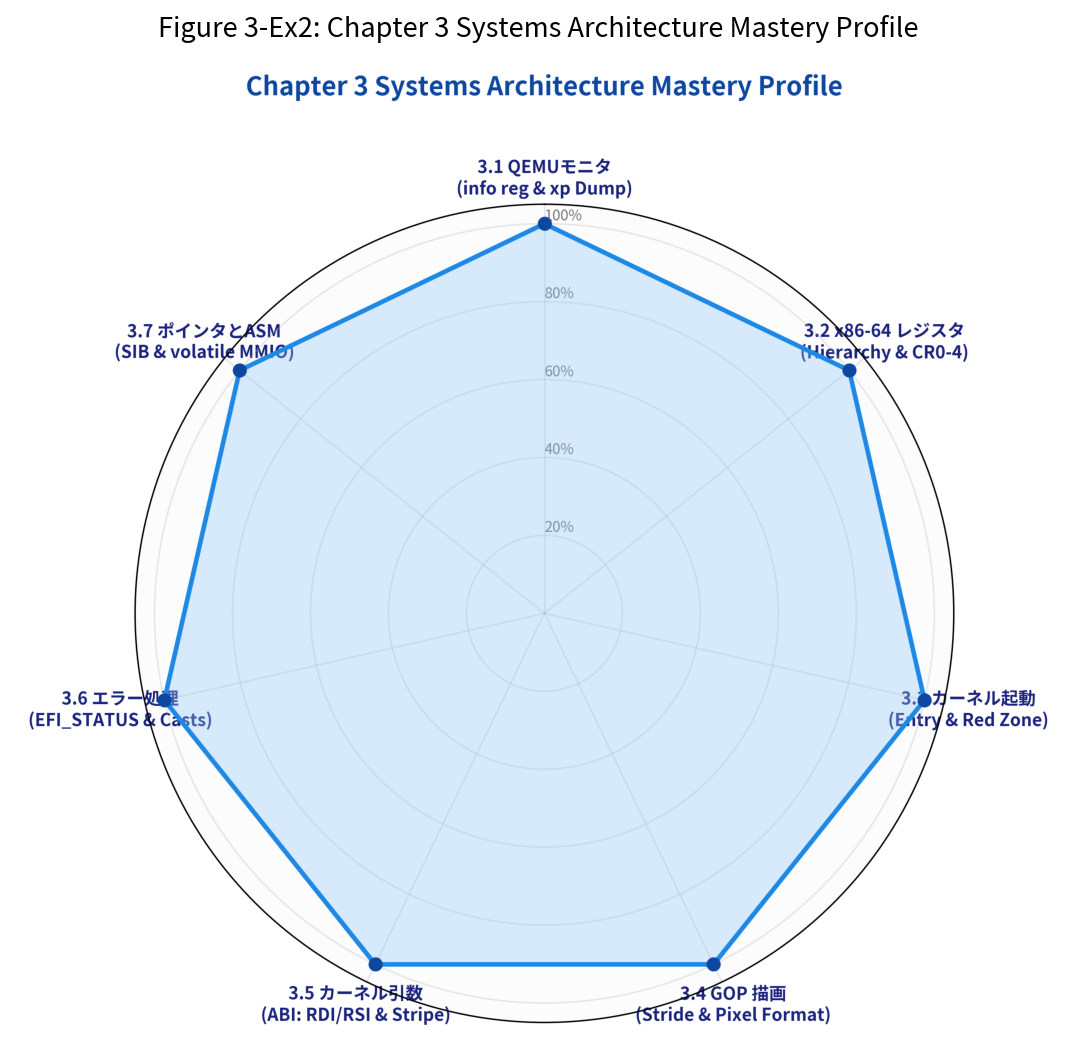

In [13]:
from common import plot_chapter3_mastery_radar

radar_path = Path("result/fig3_ex2_ch3_mastery_radar.png")
plot_chapter3_mastery_radar(radar_path, eval_result["mastery_rates"])

img_radar = plt.imread(radar_path)
plt.figure(figsize=(9, 9), dpi=150)
plt.imshow(img_radar)
plt.axis("off")
plt.title("Figure 3-Ex2: Chapter 3 Systems Architecture Mastery Profile", fontsize=13, pad=12)
plt.show()


---

## 🏆 第3章 演習完了と第4章への展望

お疲れ様でした！第3章「画面表示の練習とブートローダ」の演習をすべて完了しました。

### 第3章で獲得した主要コアスキル
1. **QEMUモニタデバッグ**: `info registers`, `xp` による物理メモリとレジスタ状態の精密ダンプ技術
2. **x86-64 レジスタ階層**: 汎用レジスタ、制御レジスタ（CR0/CR3/CR4）、および32ビットサブレジスタ書き込み時のゼロ拡張則
3. **ブートローダからカーネルへの引渡し**: `ExitBootServices()` によるUEFI脱出と関数ポインタジャンプ
4. **低レイヤの落とし穴 Red Zone**: System V AMD64 ABI の 128バイトスタック領域と `-mno-red-zone` の必須性
5. **UEFI GOP フレームバッファ**: `PixelsPerScanLine` ストライド数理と RGB/BGR 32ビットピクセルフォーマット
6. **System V AMD64 ABI**: レジスタ渡し規約（RDI, RSI, RDX, RCX, R8, R9）
7. **ポインタのアセンブリ展開**: SIB アドレッシング `[base + index*scale + disp]` とハードウェア MMIO における `volatile` の必然性

次章『**第4章 ピクセル描画とmake入門**』では、ビルド自動化ツール `make` の導入、描画処理の C++ オブジェクト指向設計（`PixelWriter` 多態性と `vtable`）、配置 `new`（Placement new）、および本格的な ELF セグメントロード機構へと進みます！
